## Modules importation

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error,mean_absolute_percentage_error, r2_score
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from datetime import datetime
from keras.models import Sequential
from keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping

import pywt
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("files/output.csv")

df["Date/Time"] = pd.to_datetime(df["Date/Time"], format='%d-%m-%Y %H:%M', errors='coerce')
df

,Date/Time,Pressure [hPa],Rel Humidity [%],40m Wind Speed [m/s],40m Wind Speed Dispersion [m/s],40m Wind Direction [°],60m Wind Speed [m/s],60m Wind Speed Dispersion [m/s],60m Wind Direction [°],70m Wind Speed [m/s],...,140m Wind Direction [°],160m Wind Speed [m/s],160m Wind Speed Dispersion [m/s],160m Wind Direction [°],180m Wind Speed [m/s],180m Wind Speed Dispersion [m/s],180m Wind Direction [°],200m Wind Speed [m/s],200m Wind Speed Dispersion [m/s],200m Wind Direction [°]
0,2018-12-01 00:10:00,1013.8,55.5,8.37,0.63,5.3,8.51,0.65,4.9,8.62,...,6.6,10.34,0.34,6.7,9.97,0.26,6.7,9.47,0.31,6.7
1,2018-12-01 00:20:00,1013.7,56.4,8.06,0.51,4.5,8.20,0.49,5.3,8.32,...,8.1,10.17,0.32,7.4,9.94,0.29,7.4,9.62,0.31,7.4
2,2018-12-01 00:30:00,1013.5,55.3,8.35,0.45,6.2,8.50,0.43,6.6,8.63,...,10.3,10.07,0.34,10.7,9.97,0.31,10.2,9.72,0.29,9.6
3,2018-12-01 00:40:00,1013.5,57.3,7.98,0.56,3.4,8.06,0.63,4.1,8.16,...,7.8,9.61,0.59,9.6,9.99,0.53,11.0,9.94,0.44,11.3
4,2018-12-01 00:50:00,1013.5,58.5,7.92,0.52,2.5,8.03,0.48,3.7,8.15,...,9.8,9.88,0.51,11.5,10.21,0.44,12.7,10.06,0.39,12.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52554,2019-11-30 23:10:00,NaN,NaN,5.15,1.88,355.8,7.29,0.54,338.5,7.39,...,343.9,9.36,0.43,346.5,10.14,0.44,348.6,10.68,0.46,350.1
52555,2019-11-30 23:20:00,NaN,NaN,4.72,2.26,359.4,7.37,0.48,336.1,7.42,...,342.4,8.82,0.43,344.1,9.57,0.45,346.4,10.28,0.49,348.7
52556,2019-11-30 23:30:00,NaN,NaN,3.58,2.05,24.1,7.03,0.44,338.2,7.11,...,344.8,8.48,0.49,346.4,9.06,0.52,347.8,9.76,0.63,349.1
52557,2019-11-30 23:40:00,NaN,NaN,3.39,1.54,37.8,6.83,0.46,333.8,6.86,...,338.9,7.43,0.43,340.7,7.89,0.46,342.6,8.44,0.63,344.8


In [3]:
df = df[["Date/Time", "60m Wind Speed [m/s]"]]
df.set_index('Date/Time',inplace=True)
df1 = df.copy()
df2 = df.copy()
df.head()

,60m Wind Speed [m/s]
Date/Time,
2018-12-01 00:10:00,8.51
2018-12-01 00:20:00,8.20
2018-12-01 00:30:00,8.50
2018-12-01 00:40:00,8.06
2018-12-01 00:50:00,8.03


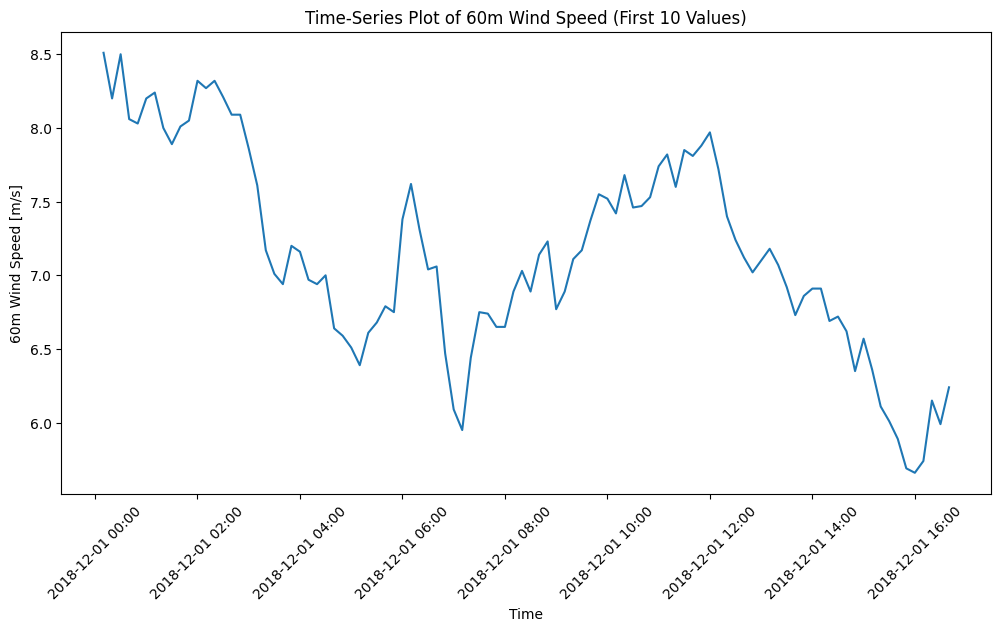

In [4]:
# Take only the first 10 rows
df_first_100 = df.head(100)

# Plot the data
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_first_100, x=df_first_100.index, y="60m Wind Speed [m/s]")

# Format the x-axis for better display
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))
plt.xticks(rotation=45)  # Rotate labels for readability

# Add labels and title
plt.xlabel("Time")
plt.ylabel("60m Wind Speed [m/s]")
plt.title("Time-Series Plot of 60m Wind Speed (First 10 Values)")

plt.show()


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 52559 entries, 2018-12-01 00:10:00 to 2019-11-30 23:50:00
Data columns (total 1 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   60m Wind Speed [m/s]  40294 non-null  float64
dtypes: float64(1)
memory usage: 821.2 KB


## Data pre-processing

In [6]:
df.isna().sum()

60m Wind Speed [m/s]    12265
dtype: int64

### Filling Null values

In [7]:
# Perform linear interpolation to fill missing values
df = df.interpolate()
df

,60m Wind Speed [m/s]
Date/Time,
2018-12-01 00:10:00,8.51
2018-12-01 00:20:00,8.20
2018-12-01 00:30:00,8.50
2018-12-01 00:40:00,8.06
2018-12-01 00:50:00,8.03
...,...
2019-11-30 23:10:00,7.29
2019-11-30 23:20:00,7.37
2019-11-30 23:30:00,7.03


In [8]:
df.isna().sum()

60m Wind Speed [m/s]    0
dtype: int64

## Checking stationarity

In [9]:
data = df["60m Wind Speed [m/s]"]

# Perform Augmented Dickey-Fuller test
result = adfuller(data)

# Extract test statistic and p-value
test_statistic = result[0]
p_value = result[1]

# Check if the data is stationary based on p-value
if p_value < 0.05:
    print("Data is stationary")
else:
    print("Data is not stationary")

Data is stationary


## ACF & PACF

Shaded part is insignificant area

Area outiside of shaded is called significant area

The point where the lines are exceeding the insignificant area, that is we are gonna consider

The ACF plot does not exhibit a sharp cutoff; instead, it gradually declines.
This indicates that 

q=0 (no significant MA terms).

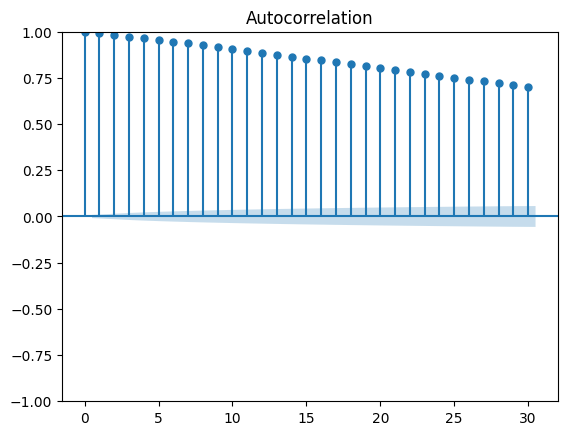

In [10]:
plot_acf(data,lags=30)
plt.show()

The PACF plot shows significant spikes at lags 1 and 2, after which the values fall within the confidence interval.
Thus, p=2.

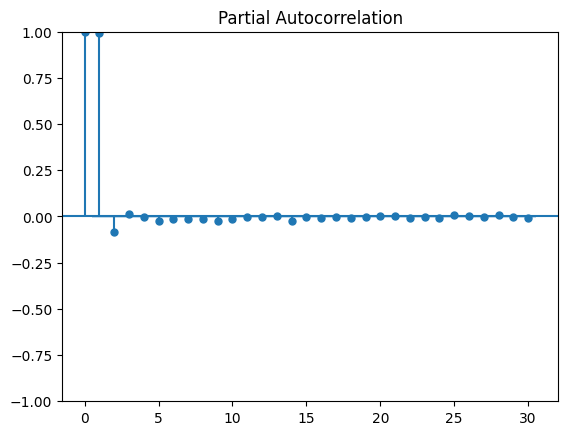

In [11]:
plot_pacf(data,lags=30)
plt.show()

## Train test split

In [12]:
split_index = int(len(df) * 0.8)

# Split the DataFrame into training and testing sets
train = df.iloc[:split_index]
test = df.iloc[split_index:]

## Build ARIMA model

In [13]:
p, d, q = 2, 0, 0

# Train the ARIMA model
model = ARIMA(train["60m Wind Speed [m/s]"], order=(p, d, q))
model = model.fit()

# Summary of the model
print(model.summary())

c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)


                                SARIMAX Results                                 
Dep. Variable:     60m Wind Speed [m/s]   No. Observations:                42047
Model:                   ARIMA(2, 0, 0)   Log Likelihood              -24231.531
Date:                  Thu, 21 Nov 2024   AIC                          48471.061
Time:                          11:18:39   BIC                          48505.647
Sample:                      12-01-2018   HQIC                         48481.983
                           - 09-18-2019                                         
Covariance Type:                    opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.7523      0.229     33.873      0.000       7.304       8.201
ar.L1          1.0722      0.002    536.940      0.000       1.068       1.076
ar.L2         -0.0817      0.002    

In [14]:
prediction = model.predict(test.index[0],test.index[-1])
df1["ARIMA prediction"] = prediction
df1

,60m Wind Speed [m/s],ARIMA prediction
Date/Time,,
2018-12-01 00:10:00,8.51,NaN
2018-12-01 00:20:00,8.20,NaN
2018-12-01 00:30:00,8.50,NaN
2018-12-01 00:40:00,8.06,NaN
2018-12-01 00:50:00,8.03,NaN
...,...,...
2019-11-30 23:10:00,7.29,7.752321
2019-11-30 23:20:00,7.37,7.752321
2019-11-30 23:30:00,7.03,7.752321


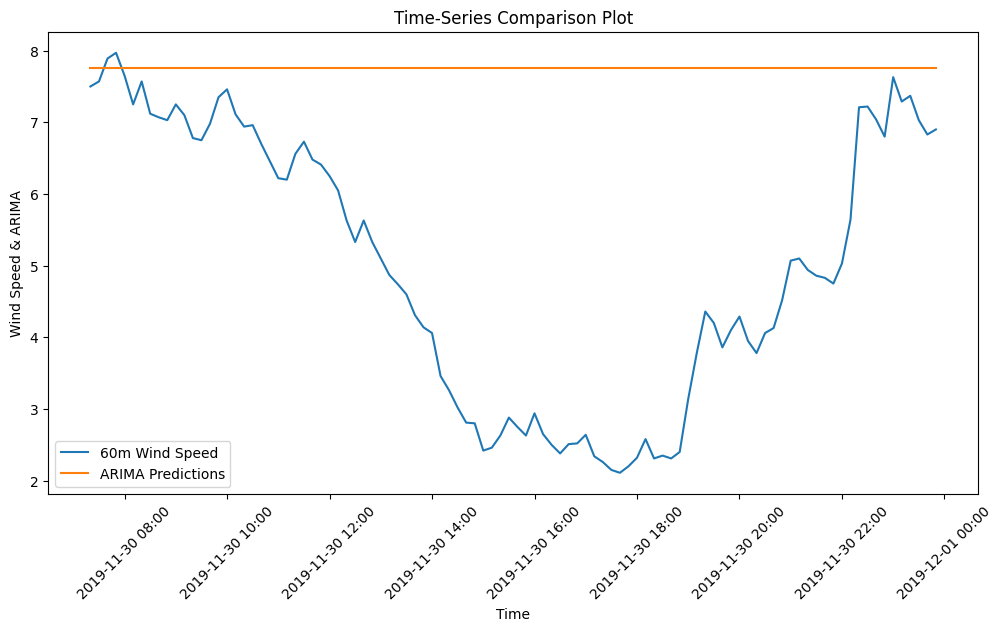

In [15]:
df_first_100 = df1.tail(100)

plt.figure(figsize=(12, 6))

# Plot the wind speed
sns.lineplot(data=df_first_100, x=df_first_100.index, y="60m Wind Speed [m/s]", label="60m Wind Speed")

# Plot the ARIMA predictions
sns.lineplot(data=df_first_100, x=df_first_100.index, y="ARIMA prediction", label="ARIMA Predictions")

# Format the x-axis for better display
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))
plt.xticks(rotation=45)  # Rotate labels for readability

# Add labels, legend, and title
plt.xlabel("Time")
plt.ylabel("Wind Speed & ARIMA")
plt.title("Time-Series Comparison Plot")
plt.legend()

# Display the plot
plt.show()

In [16]:
mae1 = mean_absolute_error(test['60m Wind Speed [m/s]'], prediction)
mse1 = mean_squared_error(test['60m Wind Speed [m/s]'], prediction)
rmse1 = np.sqrt(mse1)
mape1 = mean_absolute_percentage_error(test['60m Wind Speed [m/s]'], prediction)
r_score1 = r2_score(test['60m Wind Speed [m/s]'], prediction)

print(f'MAE: {mae1:.3f}')
print(f'MSE: {mse1:.3f}')
print(f'RMSE: {rmse1:.3f}')
print(f'MAPE: {mape1:.3f}')
print(f'R2 score: {r_score1:.3f}')

MAE: 3.001
MSE: 12.275
RMSE: 3.504
MAPE: 0.927
R2 score: -0.463


ARIMA model is not capturing the underlying patterns in the data effectively. Typically, an R² value closer to 1.0 indicates a better fit, and negative values imply poor model performance.

In [17]:
forecast_steps = 30

model = ARIMA(df["60m Wind Speed [m/s]"], order=(p, d, q))
model = model.fit()

# Forecast the next `forecast_steps` values
forecast = model.forecast(steps=forecast_steps)


forecast_index = pd.date_range(start="2019-12-01 00:00:00", periods=forecast_steps, freq='10T')

# Create a DataFrame with the forecast values and the datetime index
ARIMA_forecast = pd.DataFrame(forecast)#, index=forecast_index, columns=["ARIMA Forecast"])

# Display the forecasted DataFrame
ARIMA_forecast.rename(columns={ARIMA_forecast.columns[0]: "ARIMA forecast"},inplace=True)

c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)


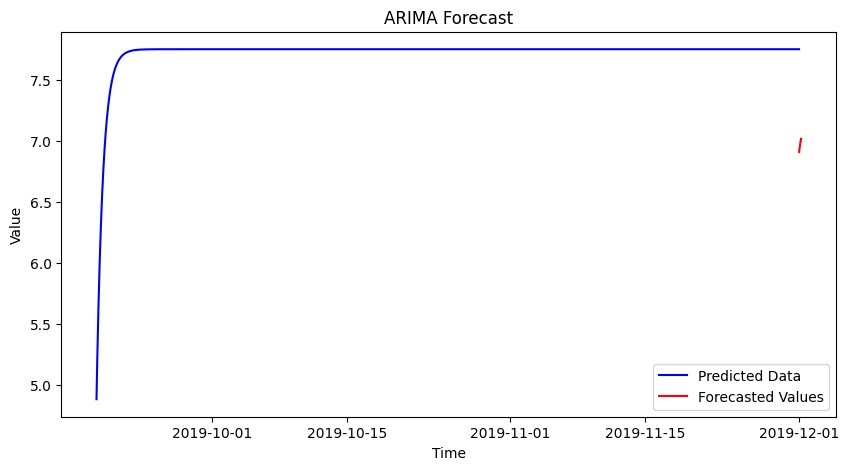

In [18]:

# Plot the original data and the forecasted values
plt.figure(figsize=(10, 5))

# Plot the original data up to the end of the test set
plt.plot(test.index, prediction, label='Predicted Data', color='blue')

# Plot the forecasted values with the new time index
plt.plot(ARIMA_forecast.index, forecast, label='Forecasted Values', color='red')
plt.xlabel('Time')
plt.ylabel('Value')
plt.title('ARIMA Forecast')
# Display the legend
plt.legend()
# Show the plot
plt.show()


In [19]:
ARIMA_MODEL = pd.concat([df1,ARIMA_forecast])
ARIMA_MODEL.tail(50)

,60m Wind Speed [m/s],ARIMA prediction,ARIMA forecast
2019-11-30 20:40:00,4.13,7.752321,NaN
2019-11-30 20:50:00,4.52,7.752321,NaN
2019-11-30 21:00:00,5.07,7.752321,NaN
2019-11-30 21:10:00,5.10,7.752321,NaN
2019-11-30 21:20:00,4.94,7.752321,NaN
2019-11-30 21:30:00,4.86,7.752321,NaN
2019-11-30 21:40:00,4.83,7.752321,NaN
2019-11-30 21:50:00,4.75,7.752321,NaN
2019-11-30 22:00:00,5.03,7.752321,NaN
2019-11-30 22:10:00,5.64,7.752321,NaN


***********************************

## Lstm

In [20]:
# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['60m Wind Speed [m/s]']])

# Create sequences
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

In [21]:
# Define sequence length
sequence_length = 20  

# Create sequences
X, y = create_sequences(scaled_data, sequence_length)

# Split the data into training and testing sets
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


#Early stopping to avoid overfitting of model
early_stop=EarlyStopping(monitor='loss',mode='min', verbose=1, patience=15, restore_best_weights=True)

# Define the LSTM model
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(sequence_length, 1)))
model.add(LSTM(50))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
model.fit(X_train, y_train, epochs=10, batch_size=32, callbacks=[early_stop])

# Evaluate the model
mse = model.evaluate(X_test, y_test)
print(f"Mean Squared Error: {mse}")

Epoch 1/10


1314/1314 [==============================] - 11s 7ms/step - loss: 0.0022
Epoch 2/10
1314/1314 [==============================] - 9s 7ms/step - loss: 5.9488e-04
Epoch 3/10
1314/1314 [==============================] - 9s 7ms/step - loss: 4.9314e-04
Epoch 4/10
1314/1314 [==============================] - 9s 7ms/step - loss: 4.7686e-04
Epoch 5/10
1314/1314 [==============================] - 9s 7ms/step - loss: 4.6912e-04
Epoch 6/10
1314/1314 [==============================] - 9s 7ms/step - loss: 4.6157e-04
Epoch 7/10
1314/1314 [==============================] - 9s 7ms/step - loss: 4.6592e-04
Epoch 8/10
1314/1314 [==============================] - 9s 7ms/step - loss: 4.5715e-04
Epoch 9/10
1314/1314 [==============================] - 9s 7ms/step - loss: 4.6148e-04
Epoch 10/10
329/329 [==============================] - 2s 3ms/step - loss: 2.9442e-04
Mean Squared Error: 0.00029441804508678615


In [22]:
# Predict on test data
y_pred_scaled = model.predict(X_test)

# Inverse transform the scaled predicted and actual values
y_pred = scaler.inverse_transform(y_pred_scaled)
y_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

101/329 [========>.....................] - ETA: 0s

329/329 [==============================] - 1s 3ms/step


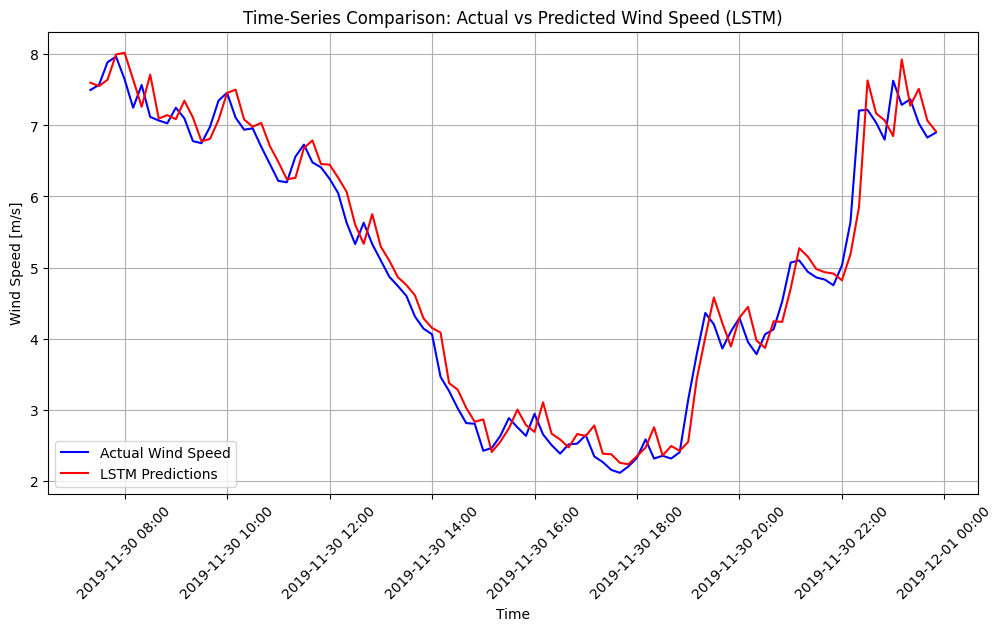

In [23]:
# Prepare the data for plotting
df_pred_actual = pd.DataFrame({
    "Actual Wind Speed": y_actual.flatten(),
    "Predicted Wind Speed": y_pred.flatten(),
}, index=df.index[-len(y_actual):])

# Use the last 100 points for visualization
df_first_100 = df_pred_actual.tail(100)

# Plot with Seaborn
plt.figure(figsize=(12, 6))

# Plot the actual wind speed
sns.lineplot(data=df_first_100, x=df_first_100.index, y="Actual Wind Speed", label="Actual Wind Speed", color='blue')

# Plot the LSTM predictions
sns.lineplot(data=df_first_100, x=df_first_100.index, y="Predicted Wind Speed", label="LSTM Predictions", color='red')

# Format the x-axis for better display
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))
plt.xticks(rotation=45)  # Rotate labels for readability

# Add labels, legend, and title
plt.xlabel("Time")
plt.ylabel("Wind Speed [m/s]")
plt.title("Time-Series Comparison: Actual vs Predicted Wind Speed (LSTM)")
plt.legend()

# Display the grid and plot
plt.grid(True)
plt.show()


In [24]:
df2["LSTM prediction"] = pd.Series(y_pred.flatten(),index=df.index[-len(y_actual):])
df2

,60m Wind Speed [m/s],LSTM prediction
Date/Time,,
2018-12-01 00:10:00,8.51,NaN
2018-12-01 00:20:00,8.20,NaN
2018-12-01 00:30:00,8.50,NaN
2018-12-01 00:40:00,8.06,NaN
2018-12-01 00:50:00,8.03,NaN
...,...,...
2019-11-30 23:10:00,7.29,7.929301
2019-11-30 23:20:00,7.37,7.278871
2019-11-30 23:30:00,7.03,7.515463


In [25]:
mae2 = mean_absolute_error(y_actual, y_pred)
mse2 = mean_squared_error(y_actual, y_pred)
rmse2 = np.sqrt(mse2)
mape2 = mean_absolute_percentage_error(y_actual, y_pred)
r_score2 = r2_score(y_actual, y_pred)

print(f'MAE: {mae2:.3f}')
print(f'MSE: {mse2:.3f}')
print(f'RMSE: {rmse2:.3f}')
print(f'MAPE: {mape2:.3f}')
print(f'R2 score: {r_score2:.3f}')

MAE: 0.213
MSE: 0.123
RMSE: 0.350
MAPE: 0.050
R2 score: 0.985


1/1 [==============================] - 0s 22ms/step


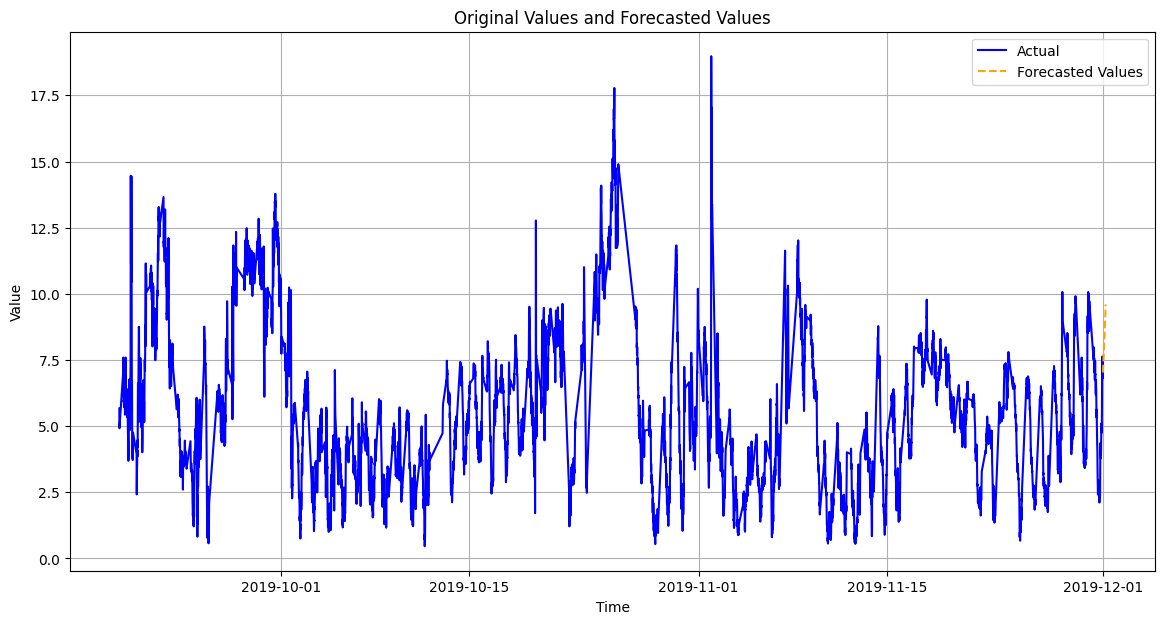

In [26]:
# Function to create sequences for forecasting
def create_forecast_sequence(data, sequence_length):
    """
    Creates the last sequence for the model to use for forecasting.
    """
    sequence = data[-sequence_length:]  # Get the last sequence_length elements from the data
    return sequence.reshape((1, sequence_length, 1))


# Number of future steps to forecast
n_future_steps = 30  # Forecasting for 30 steps (10-minute intervals, 300 minutes total)

# Prepare the initial sequence for forecasting
last_sequence = create_forecast_sequence(scaled_data, sequence_length)

# Container for storing the forecasted values
forecasted_values = []

# Iteratively forecast the future values
for _ in range(n_future_steps):
    # Predict the next value
    next_pred_scaled = model.predict(last_sequence)
    
    # Append the prediction to the forecasted values list
    forecasted_values.append(next_pred_scaled[0, 0])
    
    # Update the last_sequence by appending the predicted value and removing the first element
    next_pred_scaled_reshaped = np.array(next_pred_scaled[0, 0]).reshape((1, 1, 1))
    last_sequence = np.append(last_sequence[:, 1:, :], next_pred_scaled_reshaped, axis=1)

# Inverse transform the forecasted values to get them back to the original scale
forecasted_values = np.array(forecasted_values).reshape(-1, 1)
forecasted_values_original_scale = scaler.inverse_transform(forecasted_values)

# Create a range of forecast indices with 10-minute intervals
forecast_index = pd.date_range(
    start=df.index[-1],  # Start from the last index of the original DataFrame
    periods=n_future_steps + 1,     # Number of future steps + 1 for the starting point
    freq='10T'                      # '10T' represents 10-minute intervals
)[1:]  # Skip the first value as it's already in the original DataFrame

# Create a DataFrame for forecasted values
LSTM_forecast = pd.DataFrame({
    'LSTM Forecasted': forecasted_values_original_scale.flatten()
}, index=forecast_index)

plt.figure(figsize=(14, 7))
plt.plot(df.index[-len(y_actual):], y_actual, color='blue', label='Actual')
plt.plot(forecast_index, forecasted_values_original_scale, linestyle='--', color='orange', label='Forecasted Values')

plt.xlabel('Time')
plt.ylabel('Value')
plt.title('Original Values and Forecasted Values')
plt.legend()
plt.grid(True)
plt.show()

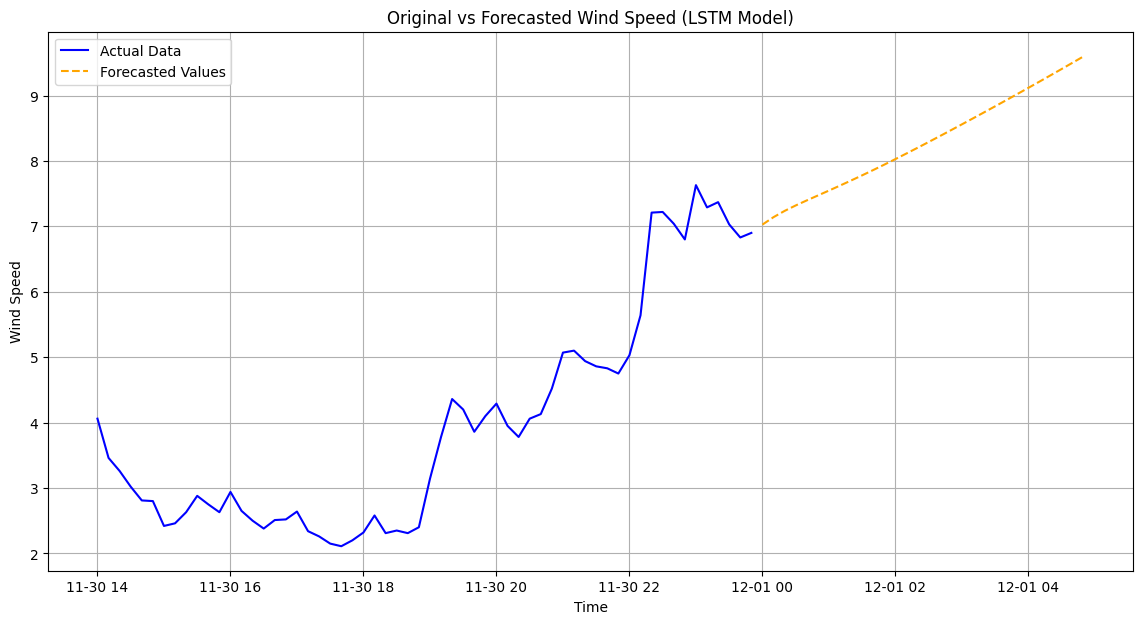

In [27]:
import matplotlib.pyplot as plt

# Number of most recent values to display (adjust this number to control the range)
n_recent = 60  # Last 60 time steps for actual data

# Slice the data to include only the most recent n values for actual data
recent_actual_data = df['60m Wind Speed [m/s]'].iloc[-n_recent:]

# Slice the forecasted values to include only the forecasted range (next 30 steps)
recent_forecasted_values = forecasted_values_original_scale[:30]
recent_forecast_index = forecast_index[:30]

# Plotting the data
plt.figure(figsize=(14, 7))

# Plot the actual data (last n_recent points)
plt.plot(recent_actual_data.index, recent_actual_data, color='blue', label='Actual Data')

# Plot the forecasted data (next n_future steps)
plt.plot(recent_forecast_index, recent_forecasted_values, linestyle='--', color='orange', label='Forecasted Values')

# Adding labels and title
plt.xlabel('Time')
plt.ylabel('Wind Speed')
plt.title('Original vs Forecasted Wind Speed (LSTM Model)')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()


In [28]:
LSTM_MODEL = pd.concat([df2,LSTM_forecast])
LSTM_MODEL.tail(50)

,60m Wind Speed [m/s],LSTM prediction,LSTM Forecasted
2019-11-30 20:40:00,4.13,4.243395,NaN
2019-11-30 20:50:00,4.52,4.234569,NaN
2019-11-30 21:00:00,5.07,4.704729,NaN
2019-11-30 21:10:00,5.10,5.271673,NaN
2019-11-30 21:20:00,4.94,5.154496,NaN
2019-11-30 21:30:00,4.86,4.978449,NaN
2019-11-30 21:40:00,4.83,4.933418,NaN
2019-11-30 21:50:00,4.75,4.915365,NaN
2019-11-30 22:00:00,5.03,4.820471,NaN
2019-11-30 22:10:00,5.64,5.185461,NaN


## Results of prediction & forecasting of Without WAVELLET transformation models

In [29]:
Models_without_transformation = pd.merge(
    ARIMA_MODEL,
    LSTM_MODEL,
    left_index=True,
    right_index=True,
    suffixes=('_arima', '_lstm')
)

Models_without_transformation.drop(columns=['60m Wind Speed [m/s]_lstm'],inplace=True)
Models_without_transformation.rename(columns={Models_without_transformation.columns[0]:'60m Wind Speed [m/s]'},inplace=True)
Models_without_transformation.to_csv("files/Models_without_transformation.csv")
Models_without_transformation.tail(50)

,60m Wind Speed [m/s],ARIMA prediction,ARIMA forecast,LSTM prediction,LSTM Forecasted
2019-11-30 20:40:00,4.13,7.752321,NaN,4.243395,NaN
2019-11-30 20:50:00,4.52,7.752321,NaN,4.234569,NaN
2019-11-30 21:00:00,5.07,7.752321,NaN,4.704729,NaN
2019-11-30 21:10:00,5.10,7.752321,NaN,5.271673,NaN
2019-11-30 21:20:00,4.94,7.752321,NaN,5.154496,NaN
2019-11-30 21:30:00,4.86,7.752321,NaN,4.978449,NaN
2019-11-30 21:40:00,4.83,7.752321,NaN,4.933418,NaN
2019-11-30 21:50:00,4.75,7.752321,NaN,4.915365,NaN
2019-11-30 22:00:00,5.03,7.752321,NaN,4.820471,NaN
2019-11-30 22:10:00,5.64,7.752321,NaN,5.185461,NaN


**************************************

**************************************

**************************************

## Applying Wavelet Transform on Data

In [30]:
tf_data = df.copy()
tf_data1 = df.copy()
tf_data2 = df.copy()
tf_data

,60m Wind Speed [m/s]
Date/Time,
2018-12-01 00:10:00,8.51
2018-12-01 00:20:00,8.20
2018-12-01 00:30:00,8.50
2018-12-01 00:40:00,8.06
2018-12-01 00:50:00,8.03
...,...
2019-11-30 23:10:00,7.29
2019-11-30 23:20:00,7.37
2019-11-30 23:30:00,7.03


## Wavelet Decomposition

In [31]:
# Wavelet Decomposition
def decompose_signal(signal, wavelet, level=1):
    coeffs = pywt.wavedec(signal, wavelet, level=level)  # Decompose signal
    approximate, details = coeffs[0], coeffs[1:]  # Separate approximate and detail coefficients
    return approximate, details, coeffs

### DB1

In [32]:
# Parameters
wavelet = 'db1'  # Choose a wavelet
level = 5  # Decomposition level

# Decompose the signal (approximate and detail coefficients)
approximate, details, coeffs = decompose_signal(tf_data['60m Wind Speed [m/s]'], wavelet, level=level)


# Set a threshold to nullify smaller coefficients (assumed to be noise)
threshold = 0.5
coeffs_thresholded = [pywt.threshold(c, threshold, mode='soft') for c in coeffs]

# Reconstruct the signal from the thresholded coefficients
denoised_signal = pywt.waverec(coeffs_thresholded, wavelet)

denoised_signal = denoised_signal[:len(tf_data)]

# Assign transformed signal to the DataFrame
tf_data["Transformed data db1"] = denoised_signal

tf_data

,60m Wind Speed [m/s],Transformed data db1
Date/Time,,
2018-12-01 00:10:00,8.51,8.004473
2018-12-01 00:20:00,8.20,8.004473
2018-12-01 00:30:00,8.50,8.004473
2018-12-01 00:40:00,8.06,8.004473
2018-12-01 00:50:00,8.03,8.004473
...,...,...
2019-11-30 23:10:00,7.29,6.882335
2019-11-30 23:20:00,7.37,6.882335
2019-11-30 23:30:00,7.03,6.878388


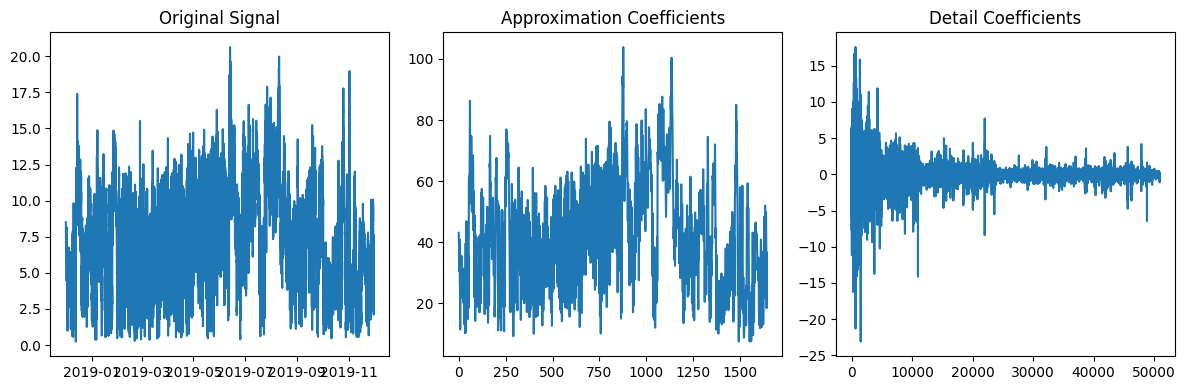

In [33]:
details = np.array([item for sublist in details for item in sublist])  # Flatten if needed

# Make sure `tf_data['60m Wind Speed [m/s]']` is in a consistent format
tf_data['60m Wind Speed [m/s]'] = tf_data['60m Wind Speed [m/s]'].values  # Convert to numpy array if it's a Series

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(tf_data['60m Wind Speed [m/s]'])
plt.title("Original Signal")

plt.subplot(1, 3, 2)
plt.plot(approximate)
plt.title("Approximation Coefficients")

plt.subplot(1, 3, 3)
plt.plot(details)
plt.title("Detail Coefficients")

plt.tight_layout()
plt.show()

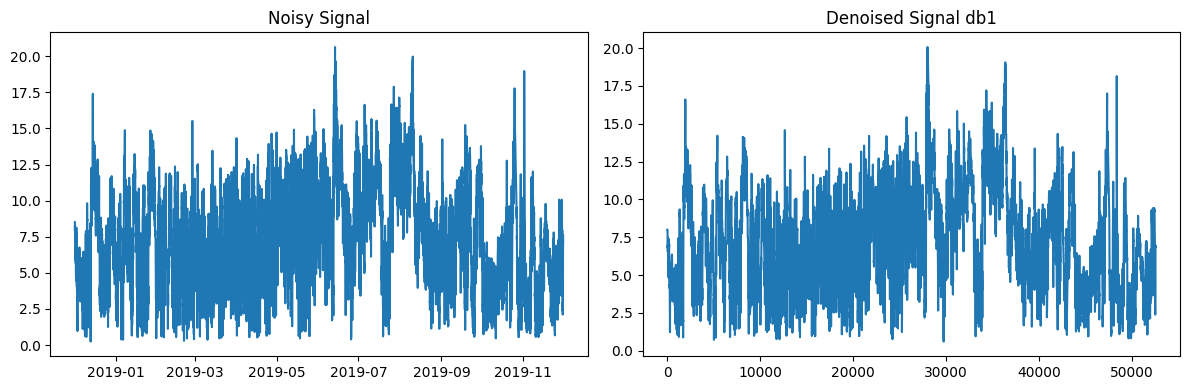

In [34]:
# Plotting the noisy and denoised signals
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(tf_data['60m Wind Speed [m/s]'])
plt.title("Noisy Signal")
plt.subplot(1, 2, 2)
plt.plot(denoised_signal)
plt.title("Denoised Signal db1")
plt.tight_layout()
plt.show()

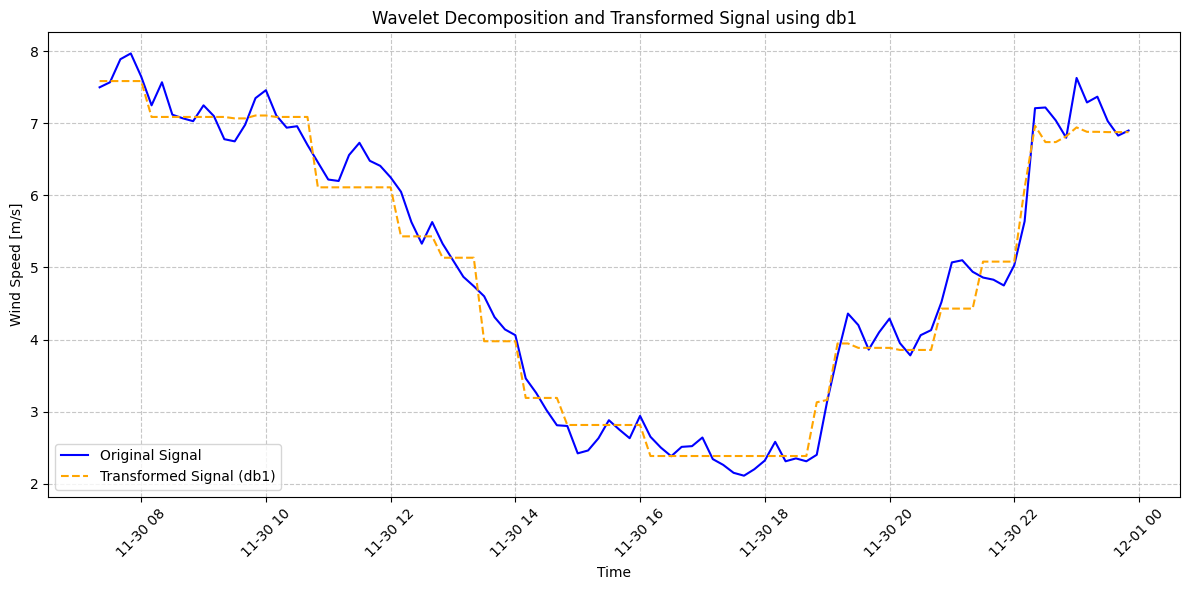

In [35]:
data = tf_data.tail(100)

# Plot original and transformed signal
plt.figure(figsize=(12, 6))

# Plotting with Seaborn
sns.lineplot(x=data.index, y=data['60m Wind Speed [m/s]'], 
label="Original Signal", color='blue')


sns.lineplot(x=data.index, y=data['Transformed data db1'], label=f"Transformed Signal ({wavelet})", color='orange', linestyle='dashed')

# plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))

# Customize x-axis to show timestamps for 100 points
plt.xticks(rotation=45)

# Add title, labels, and legend
plt.title(f'Wavelet Decomposition and Transformed Signal using {wavelet}')
plt.xlabel("Time")
plt.ylabel("Wind Speed [m/s]")
plt.legend()

# Add grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()  # Ensure no label clipping
plt.show()

### DB2

In [36]:
# Parameters
wavelet = 'db2'  # Choose a wavelet
level = 5  # Decomposition level

# Decompose the signal (approximate and detail coefficients)
approximate, details, coeffs = decompose_signal(tf_data['60m Wind Speed [m/s]'], wavelet, level=level)

# Set a threshold to nullify smaller coefficients (assumed to be noise)
threshold = 0.5
coeffs_thresholded = [pywt.threshold(c, threshold, mode='soft') for c in coeffs]

# Reconstruct the signal from the thresholded coefficients
denoised_signal_db2 = pywt.waverec(coeffs_thresholded, wavelet)

denoised_signal_db2 = denoised_signal_db2[:len(tf_data)]

# Assign transformed signal to the DataFrame
tf_data["Transformed data db2"] = denoised_signal_db2

tf_data

,60m Wind Speed [m/s],Transformed data db1,Transformed data db2
Date/Time,,,
2018-12-01 00:10:00,8.51,8.004473,8.331976
2018-12-01 00:20:00,8.20,8.004473,8.332480
2018-12-01 00:30:00,8.50,8.004473,8.222223
2018-12-01 00:40:00,8.06,8.004473,8.141644
2018-12-01 00:50:00,8.03,8.004473,8.090744
...,...,...,...
2019-11-30 23:10:00,7.29,6.882335,6.865716
2019-11-30 23:20:00,7.37,6.882335,6.718212
2019-11-30 23:30:00,7.03,6.878388,6.711877


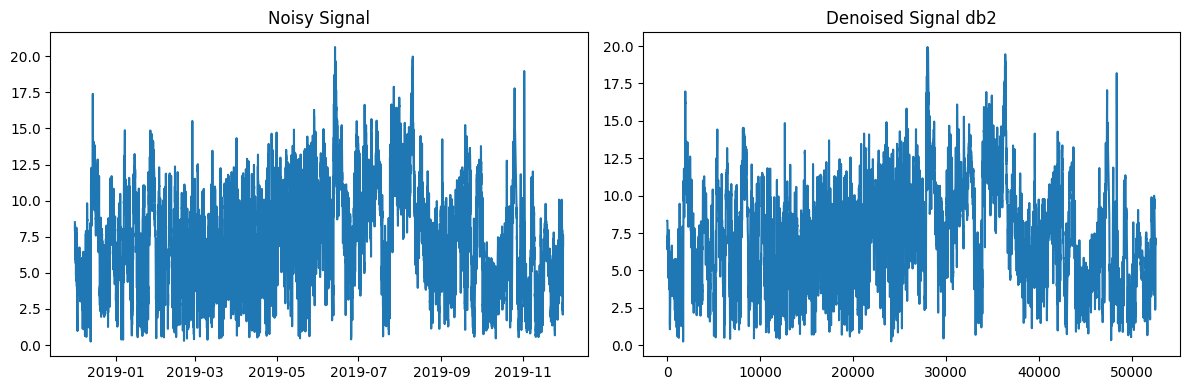

In [37]:
# Plotting the noisy and denoised signals
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(tf_data['60m Wind Speed [m/s]'])
plt.title("Noisy Signal")
plt.subplot(1, 2, 2)
plt.plot(denoised_signal_db2)
plt.title("Denoised Signal db2")
plt.tight_layout()
plt.show()

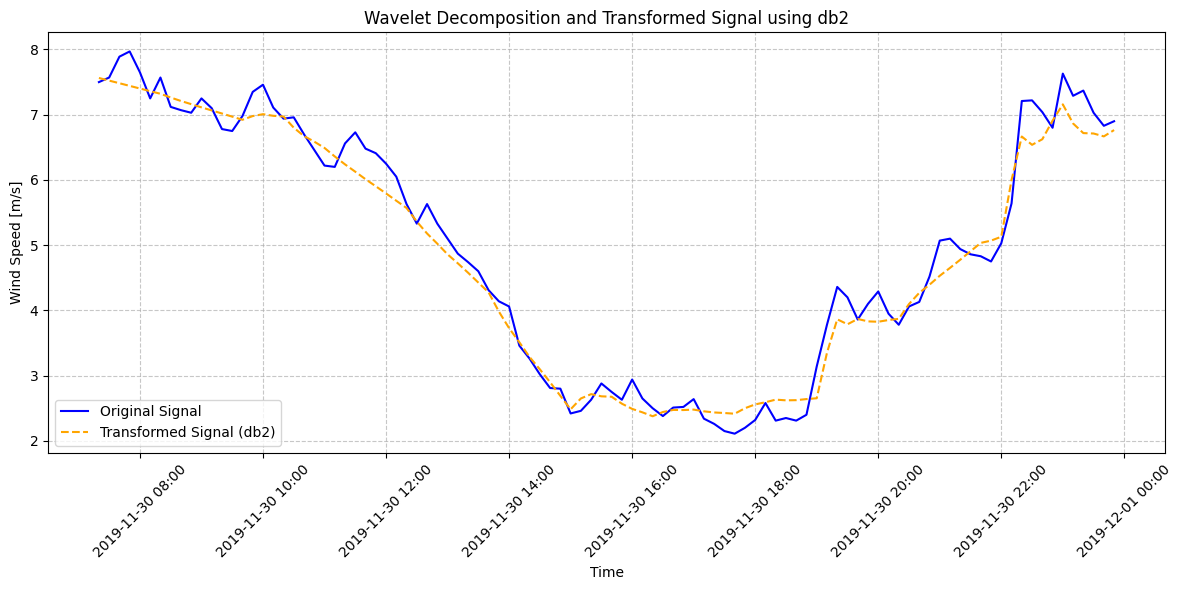

In [38]:
data = tf_data.tail(100)

# Plot original and transformed signal
plt.figure(figsize=(12, 6))

# Plotting with Seaborn
sns.lineplot(x=data.index, y=data['60m Wind Speed [m/s]'], 
label="Original Signal", color='blue')


sns.lineplot(x=data.index, y=data['Transformed data db2'], label=f"Transformed Signal ({wavelet})", color='orange', linestyle='dashed')

plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))

# Customize x-axis to show timestamps for 100 points
plt.xticks(rotation=45)

# Add title, labels, and legend
plt.title(f'Wavelet Decomposition and Transformed Signal using {wavelet}')
plt.xlabel("Time")
plt.ylabel("Wind Speed [m/s]")
plt.legend()

# Add grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()  # Ensure no label clipping
plt.show()

### HAAR

In [39]:
# Parameters
wavelet = 'haar'  # Choose a wavelet
level = 5  # Decomposition level

# Parameters
wavelet = 'db2'  # Choose a wavelet
level = 5  # Decomposition level

# Decompose the signal (approximate and detail coefficients)
approximate, details, coeffs = decompose_signal(tf_data['60m Wind Speed [m/s]'], wavelet, level=level)

# Set a threshold to nullify smaller coefficients (assumed to be noise)
threshold = 0.5
coeffs_thresholded = [pywt.threshold(c, threshold, mode='soft') for c in coeffs]

# Reconstruct the signal from the thresholded coefficients
denoised_signal_haar = pywt.waverec(coeffs_thresholded, wavelet)

denoised_signal_haar = denoised_signal_haar[:len(tf_data)]

# Assign transformed signal to the DataFrame
tf_data["Transformed data haar"] = denoised_signal_haar

tf_data

,60m Wind Speed [m/s],Transformed data db1,Transformed data db2,Transformed data haar
Date/Time,,,,
2018-12-01 00:10:00,8.51,8.004473,8.331976,8.331976
2018-12-01 00:20:00,8.20,8.004473,8.332480,8.332480
2018-12-01 00:30:00,8.50,8.004473,8.222223,8.222223
2018-12-01 00:40:00,8.06,8.004473,8.141644,8.141644
2018-12-01 00:50:00,8.03,8.004473,8.090744,8.090744
...,...,...,...,...
2019-11-30 23:10:00,7.29,6.882335,6.865716,6.865716
2019-11-30 23:20:00,7.37,6.882335,6.718212,6.718212
2019-11-30 23:30:00,7.03,6.878388,6.711877,6.711877


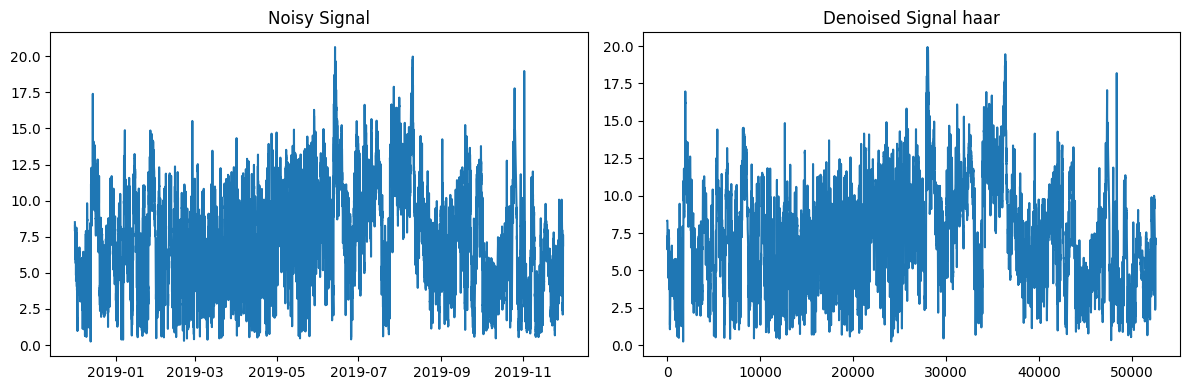

In [40]:
# Plotting the noisy and denoised signals
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(tf_data['60m Wind Speed [m/s]'])
plt.title("Noisy Signal")
plt.subplot(1, 2, 2)
plt.plot(denoised_signal_haar)
plt.title("Denoised Signal haar")
plt.tight_layout()
plt.show()

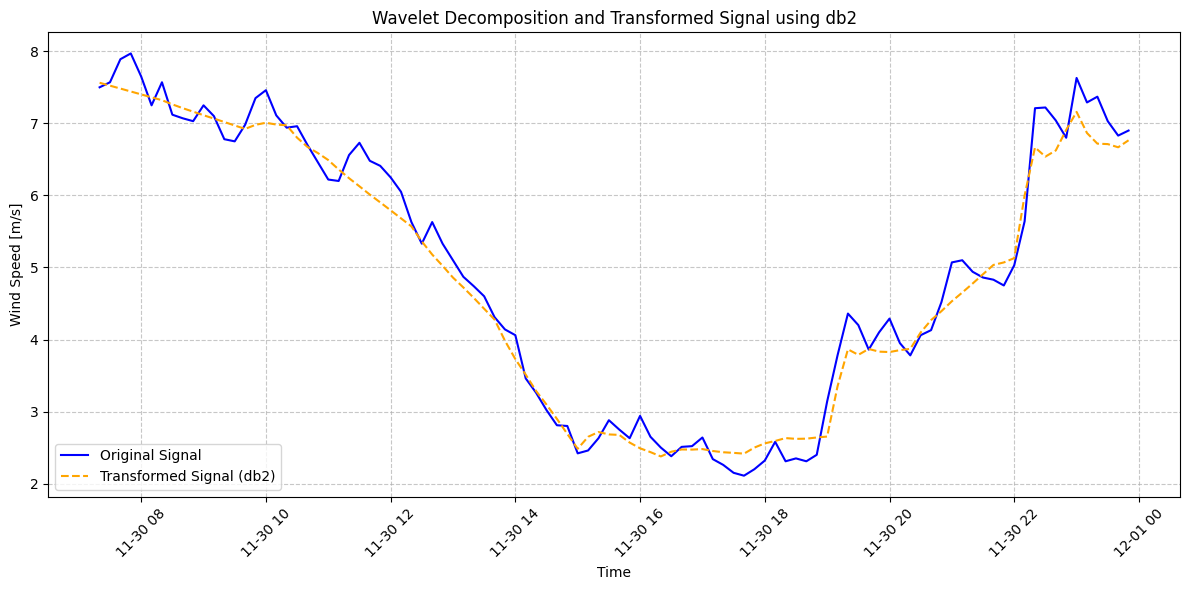

In [41]:
data = tf_data.tail(100)

# Plot original and transformed signal
plt.figure(figsize=(12, 6))

# Plotting with Seaborn
sns.lineplot(x=data.index, y=data['60m Wind Speed [m/s]'], 
label="Original Signal", color='blue')


sns.lineplot(x=data.index, y=data['Transformed data haar'], label=f"Transformed Signal ({wavelet})", color='orange', linestyle='dashed')

# plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))

# Customize x-axis to show timestamps for 100 points
plt.xticks(rotation=45)

# Add title, labels, and legend
plt.title(f'Wavelet Decomposition and Transformed Signal using {wavelet}')
plt.xlabel("Time")
plt.ylabel("Wind Speed [m/s]")
plt.legend()

# Add grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()  # Ensure no label clipping
plt.show()

db2 ---- Suitable for capturing finer details and smooth variations in the signal, which might be beneficial for models requiring richer feature sets, such as LSTM or ARIMA.
 
Starting with db2, as it typically captures both approximate and detailed variations in time-series data.

In [42]:
# Reindex denoised_signal_db2 to match the index of tf_data1
denoised_signal_db2_series = pd.Series(denoised_signal_db2, index=tf_data1.index[:len(denoised_signal_db2)])

# Assign the reindexed signal to the DataFrame
tf_data1["Transformed data db2"] = denoised_signal_db2_series


In [43]:
data = tf_data["Transformed data db2"]

# Perform Augmented Dickey-Fuller test
result = adfuller(data)

# Extract test statistic and p-value
test_statistic = result[0]
p_value = result[1]

# Check if the data is stationary based on p-value
if p_value < 0.05:
    print("Data is stationary")
else:
    print("Data is not stationary")

Data is stationary


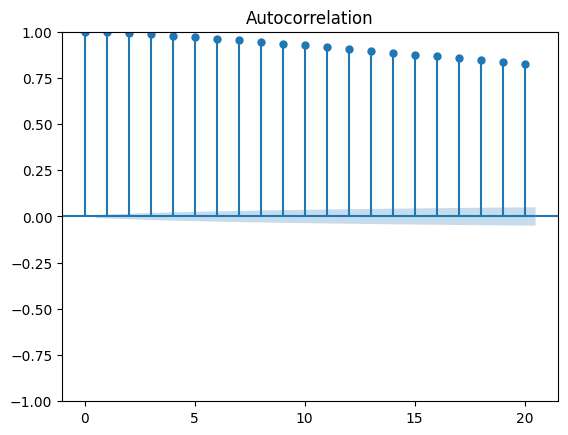

In [44]:
plot_acf(data,lags=20)
plt.show()

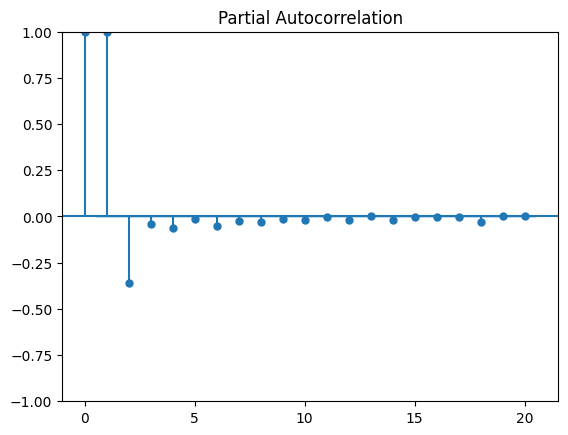

In [45]:
plot_pacf(data,lags=20)
plt.show()

In [46]:
split_index = int((len(tf_data)) * 0.8)

# Split the DataFrame into training and testing sets
train = tf_data.iloc[:split_index]
test = tf_data.iloc[split_index:]

In [47]:
p, d, q = 2, 0, 0

# Train the ARIMA model
model = ARIMA(train["Transformed data db2"], order=(p, d, q))
model = model.fit()

# Summary of the model
print(model.summary())

c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)


                                SARIMAX Results                                 
Dep. Variable:     Transformed data db2   No. Observations:                42047
Model:                   ARIMA(2, 0, 0)   Log Likelihood               -1191.142
Date:                  Thu, 21 Nov 2024   AIC                           2390.285
Time:                          11:20:46   BIC                           2424.871
Sample:                      12-01-2018   HQIC                          2401.206
                           - 09-18-2019                                         
Covariance Type:                    opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.6639      0.274     27.980      0.000       7.127       8.201
ar.L1          1.3567      0.001   1267.501      0.000       1.355       1.359
ar.L2         -0.3613      0.001   -

In [48]:
A_prediction = model.predict(start=test.index[0], end=test.index[-1])
tf_data1["ARIMAWL prediction"] = A_prediction
tf_data1

,60m Wind Speed [m/s],Transformed data db2,ARIMAWL prediction
Date/Time,,,
2018-12-01 00:10:00,8.51,8.331976,NaN
2018-12-01 00:20:00,8.20,8.332480,NaN
2018-12-01 00:30:00,8.50,8.222223,NaN
2018-12-01 00:40:00,8.06,8.141644,NaN
2018-12-01 00:50:00,8.03,8.090744,NaN
...,...,...,...
2019-11-30 23:10:00,7.29,6.865716,7.663892
2019-11-30 23:20:00,7.37,6.718212,7.663892
2019-11-30 23:30:00,7.03,6.711877,7.663892


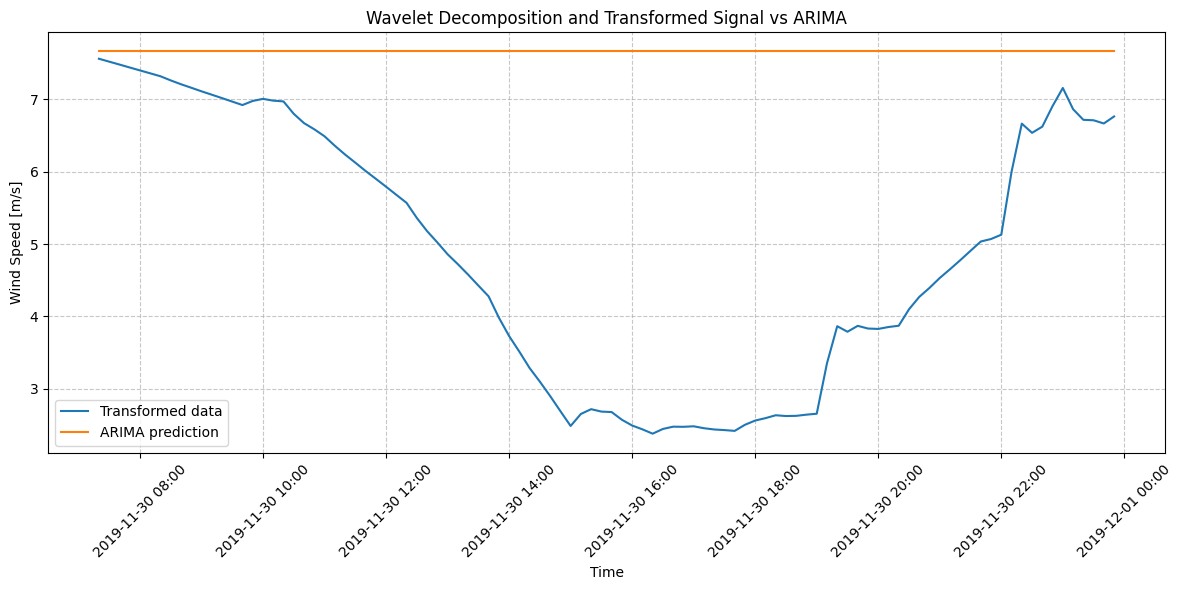

In [51]:
data = tf_data1.tail(100)

plt.figure(figsize=(12, 6))

sns.lineplot(data=data,x=data.index,y='Transformed data db2',label="Transformed data")
sns.lineplot(data=data,x=data.index,y='ARIMAWL prediction',label='ARIMA prediction')

plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))

# Customize x-axis to show timestamps for 100 points
plt.xticks(rotation=45)

# Add title, labels, and legend
plt.title(f'Wavelet Decomposition and Transformed Signal vs ARIMA')
plt.xlabel("Time")
plt.ylabel("Wind Speed [m/s]")
plt.legend()

# Add grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()  # Ensure no label clipping
plt.show()

In [52]:
mae3 = mean_absolute_error(test['Transformed data db2'], A_prediction)
mse3 = mean_squared_error(test['Transformed data db2'], A_prediction)
rmse3 = np.sqrt(mse3)
mape3 = mean_absolute_percentage_error(test['Transformed data db2'], A_prediction)
r_score3 = r2_score(test['Transformed data db2'], A_prediction)

print(f'MAE: {mae3:.3f}')
print(f'MSE: {mse3:.3f}')
print(f'RMSE: {rmse3:.3f}')
print(f'MAPE: {mape3:.3f}')
print(f'R2 score: {r_score3:.3f}')

MAE: 2.982
MSE: 12.102
RMSE: 3.479
MAPE: 0.927
R2 score: -0.473


c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)
c:\Users\91997\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 10T will be used.
  self._init_dates(dates, freq)


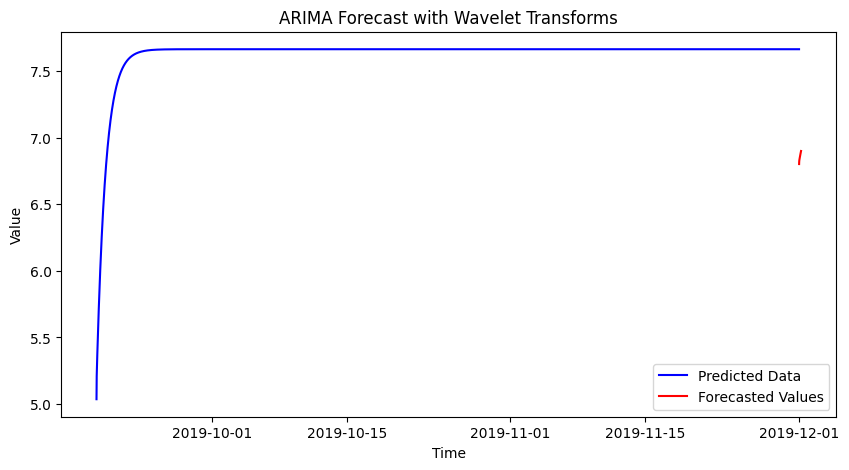

In [54]:
forecast_steps = 30

model = ARIMA(tf_data["Transformed data db2"], order=(p, d, q))
model = model.fit()

# Forecast the next `forecast_steps` values
forecast = model.forecast(steps=forecast_steps)


forecast_index = pd.date_range(start="2019-12-01 00:00:00", periods=forecast_steps, freq='10T')

# Create a DataFrame with the forecast values and the datetime index
ARIMAWL_forecast = pd.DataFrame(forecast)#, index=forecast_index, columns=["ARIMA Forecast"])

# Display the forecasted DataFrame
ARIMAWL_forecast.rename(columns={ARIMAWL_forecast.columns[0]: "ARIMAWL forecast"},inplace=True)

# Plot the original data and the forecasted values
plt.figure(figsize=(10, 5))

# Plot the original data up to the end of the test set
plt.plot(test.index, A_prediction, label='Predicted Data', color='blue')

# Plot the forecasted values with the new time index
plt.plot(ARIMAWL_forecast.index, forecast, label='Forecasted Values', color='red')
plt.xlabel('Time')
plt.ylabel('Value')
plt.title('ARIMA Forecast with Wavelet Transforms')
# Display the legend
plt.legend()
# Show the plot
plt.show()



In [55]:
ARIMAWL_MODEL = pd.concat([tf_data1,ARIMAWL_forecast],axis=0)
ARIMAWL_MODEL.tail(50)

,60m Wind Speed [m/s],Transformed data db2,ARIMAWL prediction,ARIMAWL forecast
2019-11-30 20:40:00,4.13,4.269168,7.663892,NaN
2019-11-30 20:50:00,4.52,4.393826,7.663892,NaN
2019-11-30 21:00:00,5.07,4.530990,7.663892,NaN
2019-11-30 21:10:00,5.10,4.651834,7.663892,NaN
2019-11-30 21:20:00,4.94,4.777052,7.663892,NaN
2019-11-30 21:30:00,4.86,4.906642,7.663892,NaN
2019-11-30 21:40:00,4.83,5.035060,7.663892,NaN
2019-11-30 21:50:00,4.75,5.069612,7.663892,NaN
2019-11-30 22:00:00,5.03,5.129315,7.663892,NaN
2019-11-30 22:10:00,5.64,5.999341,7.663892,NaN


*******************

*******************

*******************

## Lstm

In [56]:
# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(tf_data[['Transformed data db2']])

# Create sequences
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

In [57]:
# Define sequence length
sequence_length = 20

# Create sequences
X, y = create_sequences(scaled_data, sequence_length)

# Split the data into training and testing sets
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


#Early stopping to avoid overfitting of model
early_stop=EarlyStopping(monitor='loss',mode='min', verbose=1, patience=15, restore_best_weights=True)

# Define the LSTM model
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(sequence_length, 1)))
model.add(LSTM(50))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
model.fit(X_train, y_train, epochs=10, batch_size=32, callbacks=[early_stop])

# Evaluate the model
mse = model.evaluate(X_test, y_test)
print(f"Mean Squared Error: {mse}")

Epoch 1/10
 159/1314 [==>...........................] - ETA: 10s - loss: 0.0087

1314/1314 [==============================] - 11s 7ms/step - loss: 0.0018
Epoch 2/10
1314/1314 [==============================] - 9s 7ms/step - loss: 3.1672e-04
Epoch 3/10
1314/1314 [==============================] - 9s 7ms/step - loss: 2.1441e-04
Epoch 4/10
1314/1314 [==============================] - 9s 7ms/step - loss: 1.8738e-04
Epoch 5/10
1314/1314 [==============================] - 9s 7ms/step - loss: 1.8239e-04
Epoch 6/10
1314/1314 [==============================] - 9s 7ms/step - loss: 1.7720e-04
Epoch 7/10
1314/1314 [==============================] - 9s 7ms/step - loss: 1.7212e-04
Epoch 8/10
1314/1314 [==============================] - 9s 7ms/step - loss: 1.7026e-04
Epoch 9/10
1314/1314 [==============================] - 9s 7ms/step - loss: 1.6939e-04
Epoch 10/10
329/329 [==============================] - 2s 3ms/step - loss: 1.2972e-04
Mean Squared Error: 0.00012971954129170626


In [58]:
# Predict on test data
y_pred_scaled = model.predict(X_test)

# Inverse transform the scaled predicted and actual values
y_pred = scaler.inverse_transform(y_pred_scaled)
y_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

110/329 [=========>....................] - ETA: 0s

329/329 [==============================] - 2s 3ms/step


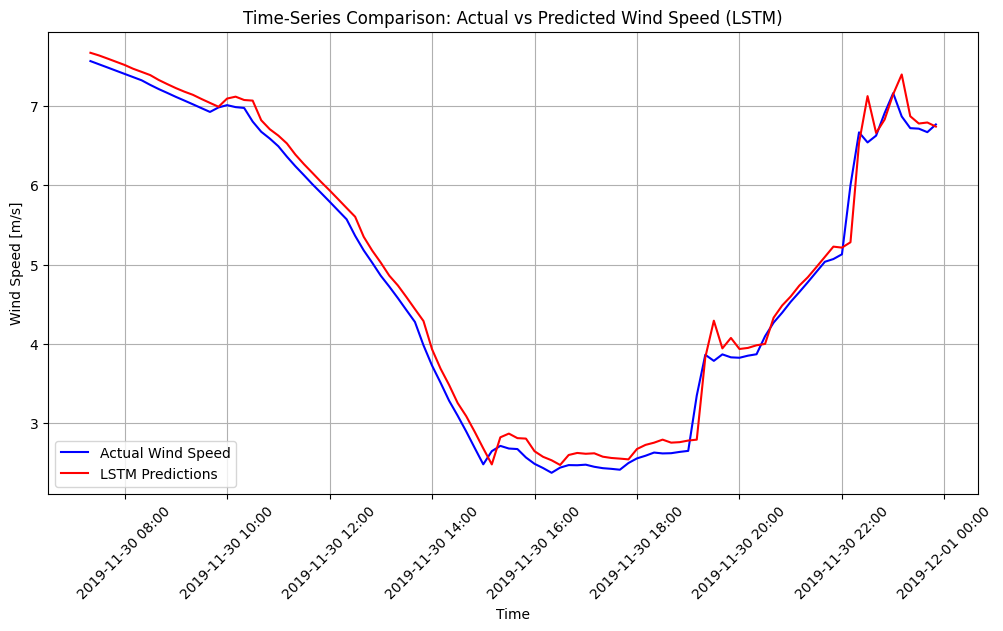

In [59]:
# Prepare the data for plotting
df_pred_actual = pd.DataFrame({
    "Actual Wind Speed": y_actual.flatten(),
    "Predicted Wind Speed": y_pred.flatten(),
}, index=df.index[-len(y_actual):])

# Use the last 100 points for visualization
df_first_100 = df_pred_actual.tail(100)

# Plot with Seaborn
plt.figure(figsize=(12, 6))

# Plot the actual wind speed
sns.lineplot(data=df_first_100, x=df_first_100.index, y="Actual Wind Speed", label="Actual Wind Speed", color='blue')

# Plot the LSTM predictions
sns.lineplot(data=df_first_100, x=df_first_100.index, y="Predicted Wind Speed", label="LSTM Predictions", color='red')

# Format the x-axis for better display
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m-%d %H:%M'))
plt.xticks(rotation=45)  # Rotate labels for readability

# Add labels, legend, and title
plt.xlabel("Time")
plt.ylabel("Wind Speed [m/s]")
plt.title("Time-Series Comparison: Actual vs Predicted Wind Speed (LSTM)")
plt.legend()

# Display the grid and plot
plt.grid(True)
plt.show()


In [60]:
tf_data2["LSTMWL prediction"] = pd.Series(y_pred.flatten(),index=df.index[-len(y_actual):])
tf_data2

,60m Wind Speed [m/s],LSTMWL prediction
Date/Time,,
2018-12-01 00:10:00,8.51,NaN
2018-12-01 00:20:00,8.20,NaN
2018-12-01 00:30:00,8.50,NaN
2018-12-01 00:40:00,8.06,NaN
2018-12-01 00:50:00,8.03,NaN
...,...,...
2019-11-30 23:10:00,7.29,7.394338
2019-11-30 23:20:00,7.37,6.868335
2019-11-30 23:30:00,7.03,6.776541


In [61]:
mae4 = mean_absolute_error(y_actual, y_pred)
mse4 = mean_squared_error(y_actual, y_pred)
rmse4 = np.sqrt(mse4)
mape4 = mean_absolute_percentage_error(y_actual, y_pred)
r_score4 = r2_score(y_actual, y_pred)

print(f'MAE: {mae4:.3f}')
print(f'MSE: {mse4:.3f}')
print(f'RMSE: {rmse4:.3f}')
print(f'MAPE: {mape4:.3f}')
print(f'R4 score: {r_score4:.3f}')

MAE: 0.138
MSE: 0.050
RMSE: 0.224
MAPE: 0.035
R4 score: 0.994


1/1 [==============================] - 0s 18ms/step


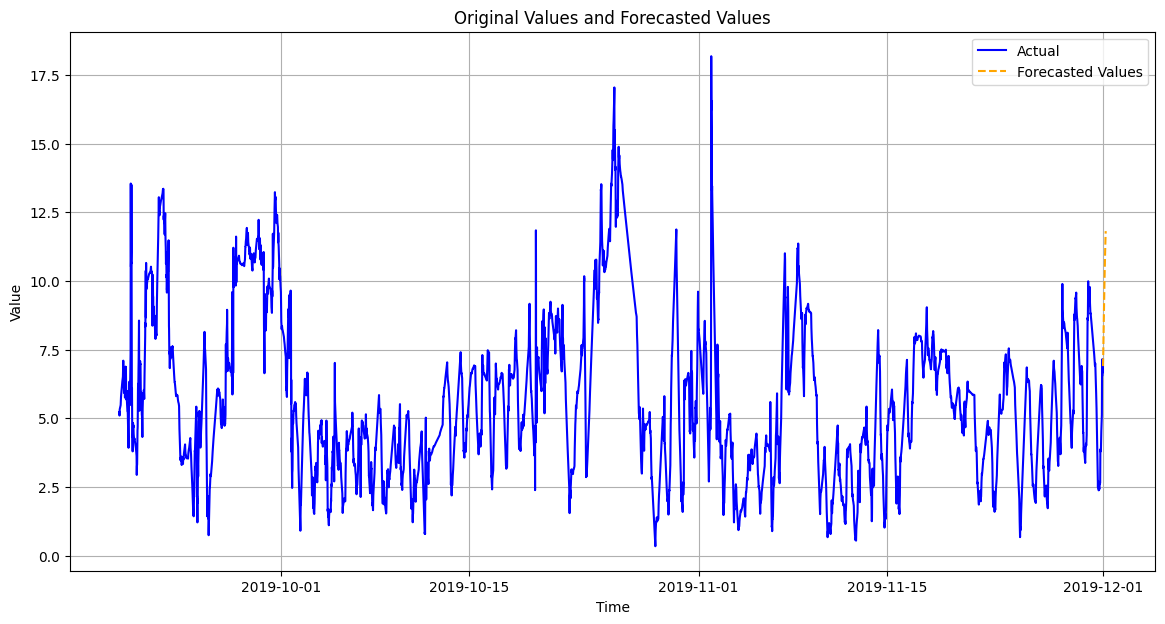

In [62]:
# Function to create sequences for forecasting
def create_forecast_sequence(data, sequence_length):
    """
    Creates the last sequence for the model to use for forecasting.
    """
    sequence = data[-sequence_length:]  # Get the last sequence_length elements from the data
    return sequence.reshape((1, sequence_length, 1))


# Number of future steps to forecast
n_future_steps = 30  # Forecasting for 30 steps (10-minute intervals, 300 minutes total)

# Prepare the initial sequence for forecasting
last_sequence = create_forecast_sequence(scaled_data, sequence_length)

# Container for storing the forecasted values
forecasted_values = []

# Iteratively forecast the future values
for _ in range(n_future_steps):
    # Predict the next value
    next_pred_scaled = model.predict(last_sequence)
    
    # Append the prediction to the forecasted values list
    forecasted_values.append(next_pred_scaled[0, 0])
    
    # Update the last_sequence by appending the predicted value and removing the first element
    next_pred_scaled_reshaped = np.array(next_pred_scaled[0, 0]).reshape((1, 1, 1))
    last_sequence = np.append(last_sequence[:, 1:, :], next_pred_scaled_reshaped, axis=1)

# Inverse transform the forecasted values to get them back to the original scale
forecasted_values = np.array(forecasted_values).reshape(-1, 1)
forecasted_values_original_scale = scaler.inverse_transform(forecasted_values)

# Create a range of forecast indices with 10-minute intervals
forecast_index = pd.date_range(
    start=df.index[-1],  # Start from the last index of the original DataFrame
    periods=n_future_steps + 1,     # Number of future steps + 1 for the starting point
    freq='10T'                      # '10T' represents 10-minute intervals
)[1:]  # Skip the first value as it's already in the original DataFrame

# Create a DataFrame for forecasted values
LSTMWL_forecast = pd.DataFrame({
    'LSTMWL Forecasted': forecasted_values_original_scale.flatten()
}, index=forecast_index)

plt.figure(figsize=(14, 7))
plt.plot(df.index[-len(y_actual):], y_actual, color='blue', label='Actual')
plt.plot(forecast_index, forecasted_values_original_scale, linestyle='--', color='orange', label='Forecasted Values')

plt.xlabel('Time')
plt.ylabel('Value')
plt.title('Original Values and Forecasted Values')
plt.legend()
plt.grid(True)
plt.show()

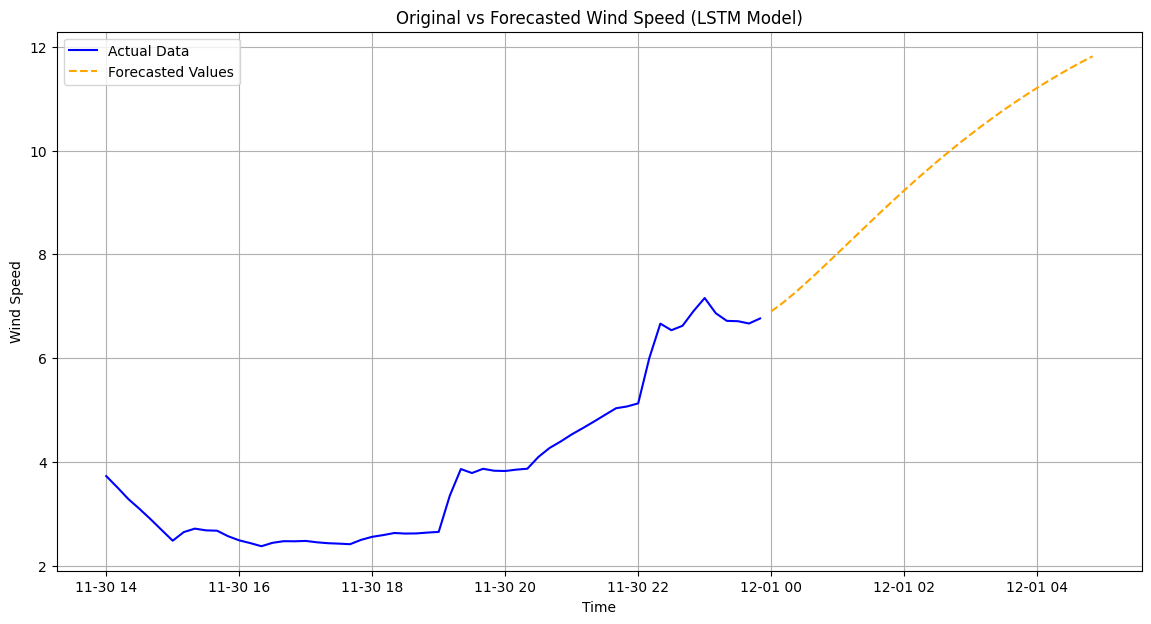

In [63]:
import matplotlib.pyplot as plt

# Number of most recent values to display (adjust this number to control the range)
n_recent = 60  # Last 60 time steps for actual data

# Slice the data to include only the most recent n values for actual data
recent_actual_data = tf_data['Transformed data db2'].iloc[-n_recent:]

# Slice the forecasted values to include only the forecasted range (next 30 steps)
recent_forecasted_values = forecasted_values_original_scale[:30]
recent_forecast_index = forecast_index[:30]

# Plotting the data
plt.figure(figsize=(14, 7))

# Plot the actual data (last n_recent points)
plt.plot(recent_actual_data.index, recent_actual_data, color='blue', label='Actual Data')

# Plot the forecasted data (next n_future steps)
plt.plot(recent_forecast_index, recent_forecasted_values, linestyle='--', color='orange', label='Forecasted Values')

# Adding labels and title
plt.xlabel('Time')
plt.ylabel('Wind Speed')
plt.title('Original vs Forecasted Wind Speed (LSTM Model)')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()


In [64]:
LSTMWL_MODEL = pd.concat([tf_data2,LSTMWL_forecast])
LSTMWL_MODEL.tail(50)


,60m Wind Speed [m/s],LSTMWL prediction,LSTMWL Forecasted
2019-11-30 20:40:00,4.13,4.331093,NaN
2019-11-30 20:50:00,4.52,4.484456,NaN
2019-11-30 21:00:00,5.07,4.597917,NaN
2019-11-30 21:10:00,5.10,4.733967,NaN
2019-11-30 21:20:00,4.94,4.840009,NaN
2019-11-30 21:30:00,4.86,4.966878,NaN
2019-11-30 21:40:00,4.83,5.096269,NaN
2019-11-30 21:50:00,4.75,5.225894,NaN
2019-11-30 22:00:00,5.03,5.213295,NaN
2019-11-30 22:10:00,5.64,5.280940,NaN


## Results of prediction & forecasting of WAVELLET transformation models

In [65]:
Models_with_transformation = pd.merge(
    ARIMAWL_MODEL,
    LSTMWL_MODEL,
    left_index=True,
    right_index=True,
    suffixes=('_arima', '_lstm')
)

Models_with_transformation.drop(columns=['60m Wind Speed [m/s]_lstm'],inplace=True)
Models_with_transformation.rename(columns={Models_with_transformation.columns[0]:'60m Wind Speed [m/s]'},inplace=True)
Models_with_transformation.to_csv("files/Models_with_transformation.csv")
Models_with_transformation.tail(50)

,60m Wind Speed [m/s],Transformed data db2,ARIMAWL prediction,ARIMAWL forecast,LSTMWL prediction,LSTMWL Forecasted
2019-11-30 20:40:00,4.13,4.269168,7.663892,NaN,4.331093,NaN
2019-11-30 20:50:00,4.52,4.393826,7.663892,NaN,4.484456,NaN
2019-11-30 21:00:00,5.07,4.530990,7.663892,NaN,4.597917,NaN
2019-11-30 21:10:00,5.10,4.651834,7.663892,NaN,4.733967,NaN
2019-11-30 21:20:00,4.94,4.777052,7.663892,NaN,4.840009,NaN
2019-11-30 21:30:00,4.86,4.906642,7.663892,NaN,4.966878,NaN
2019-11-30 21:40:00,4.83,5.035060,7.663892,NaN,5.096269,NaN
2019-11-30 21:50:00,4.75,5.069612,7.663892,NaN,5.225894,NaN
2019-11-30 22:00:00,5.03,5.129315,7.663892,NaN,5.213295,NaN
2019-11-30 22:10:00,5.64,5.999341,7.663892,NaN,5.280940,NaN


## Results of prediction & forecasting of all models

In [66]:
ALL_Models = pd.merge(
    Models_without_transformation,
    Models_with_transformation,
    left_index=True,
    right_index=True,
    suffixes=('_arima', '_lstm')
)

ALL_Models.drop(columns=['60m Wind Speed [m/s]_lstm'],inplace=True)
ALL_Models.rename(columns={ALL_Models.columns[0]:'60m Wind Speed [m/s]'},inplace=True)
ALL_Models.to_csv("files/ALL_Models.csv")
ALL_Models.tail(50)

,60m Wind Speed [m/s],ARIMA prediction,ARIMA forecast,LSTM prediction,LSTM Forecasted,Transformed data db2,ARIMAWL prediction,ARIMAWL forecast,LSTMWL prediction,LSTMWL Forecasted
2019-11-30 20:40:00,4.13,7.752321,NaN,4.243395,NaN,4.269168,7.663892,NaN,4.331093,NaN
2019-11-30 20:50:00,4.52,7.752321,NaN,4.234569,NaN,4.393826,7.663892,NaN,4.484456,NaN
2019-11-30 21:00:00,5.07,7.752321,NaN,4.704729,NaN,4.530990,7.663892,NaN,4.597917,NaN
2019-11-30 21:10:00,5.10,7.752321,NaN,5.271673,NaN,4.651834,7.663892,NaN,4.733967,NaN
2019-11-30 21:20:00,4.94,7.752321,NaN,5.154496,NaN,4.777052,7.663892,NaN,4.840009,NaN
2019-11-30 21:30:00,4.86,7.752321,NaN,4.978449,NaN,4.906642,7.663892,NaN,4.966878,NaN
2019-11-30 21:40:00,4.83,7.752321,NaN,4.933418,NaN,5.035060,7.663892,NaN,5.096269,NaN
2019-11-30 21:50:00,4.75,7.752321,NaN,4.915365,NaN,5.069612,7.663892,NaN,5.225894,NaN
2019-11-30 22:00:00,5.03,7.752321,NaN,4.820471,NaN,5.129315,7.663892,NaN,5.213295,NaN
2019-11-30 22:10:00,5.64,7.752321,NaN,5.185461,NaN,5.999341,7.663892,NaN,5.280940,NaN


******************************

******************************

******************************

## Comparison


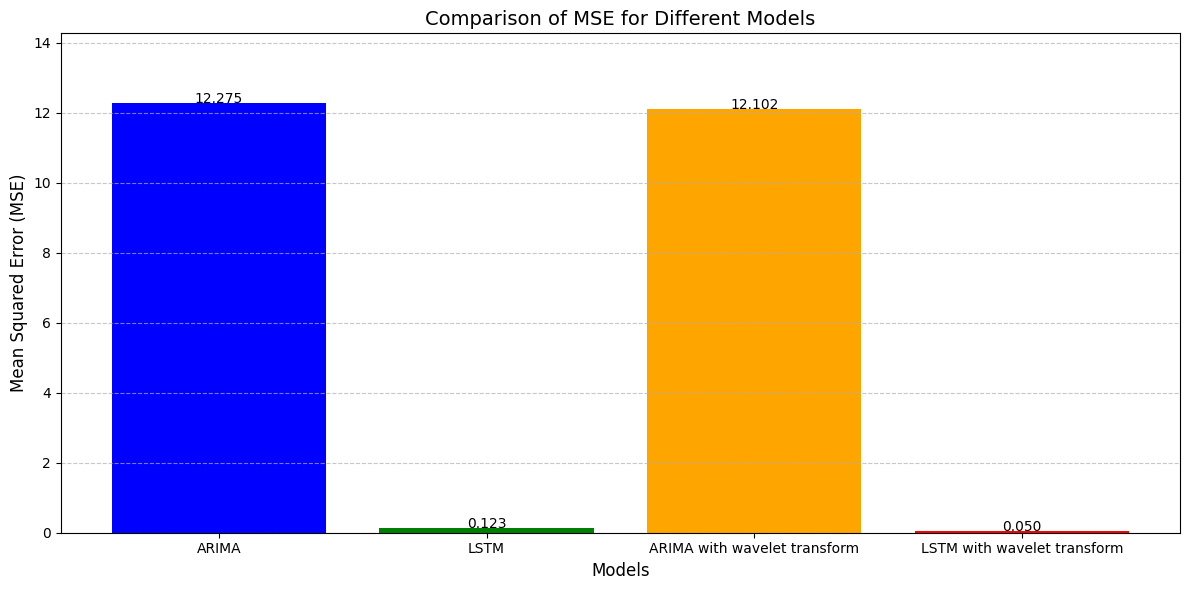

In [67]:
models = ['ARIMA', 'LSTM', 'ARIMA with wavelet transform', 'LSTM with wavelet transform']
mse_values = [mse1, mse2, mse3, mse4]

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(models, mse_values, color=['blue', 'green', 'orange', 'red'])

# Add labels and title
plt.xlabel('Models', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.title('Comparison of MSE for Different Models', fontsize=14)
plt.ylim(0, max(mse_values) + 2)  # Adjust y-axis for better visualization

# Annotate bars with MSE values
for i, v in enumerate(mse_values):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=10)

# Show the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


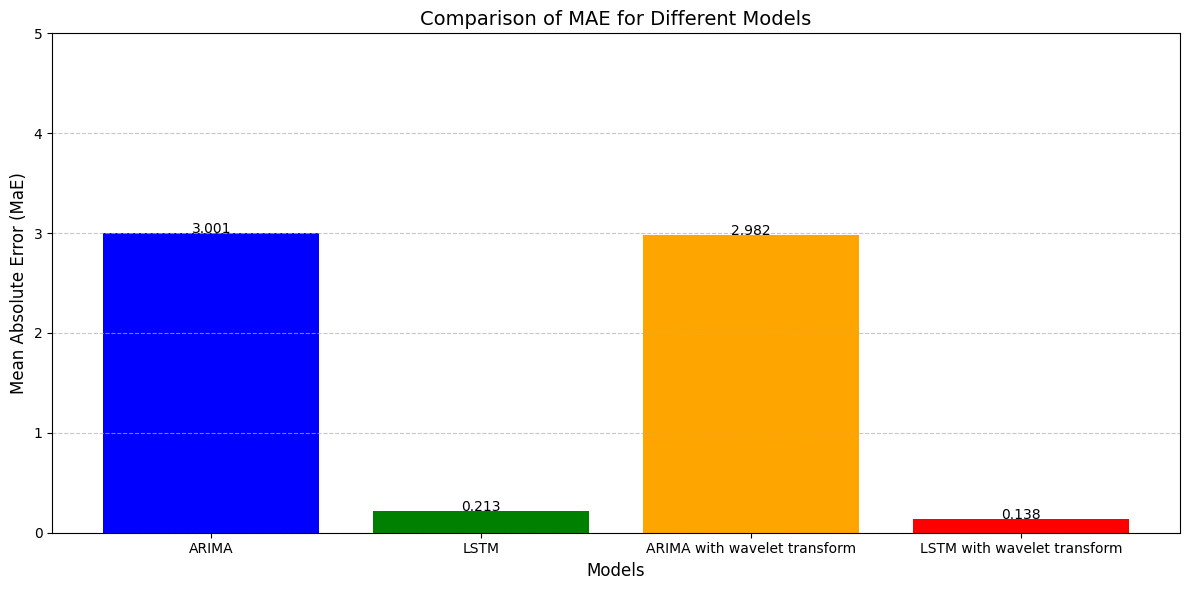

In [68]:
models = ['ARIMA', 'LSTM', 'ARIMA with wavelet transform', 'LSTM with wavelet transform']
mae_values = [mae1, mae2, mae3, mae4]

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(models, mae_values, color=['blue', 'green', 'orange', 'red'])

# Add labels and title
plt.xlabel('Models', fontsize=12)
plt.ylabel('Mean Absolute Error (MaE)', fontsize=12)
plt.title('Comparison of MAE for Different Models', fontsize=14)
plt.ylim(0, max(mae_values) + 2)  # Adjust y-axis for better visualization

# Annotate bars with MSE values
for i, v in enumerate(mae_values):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=10)

# Show the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

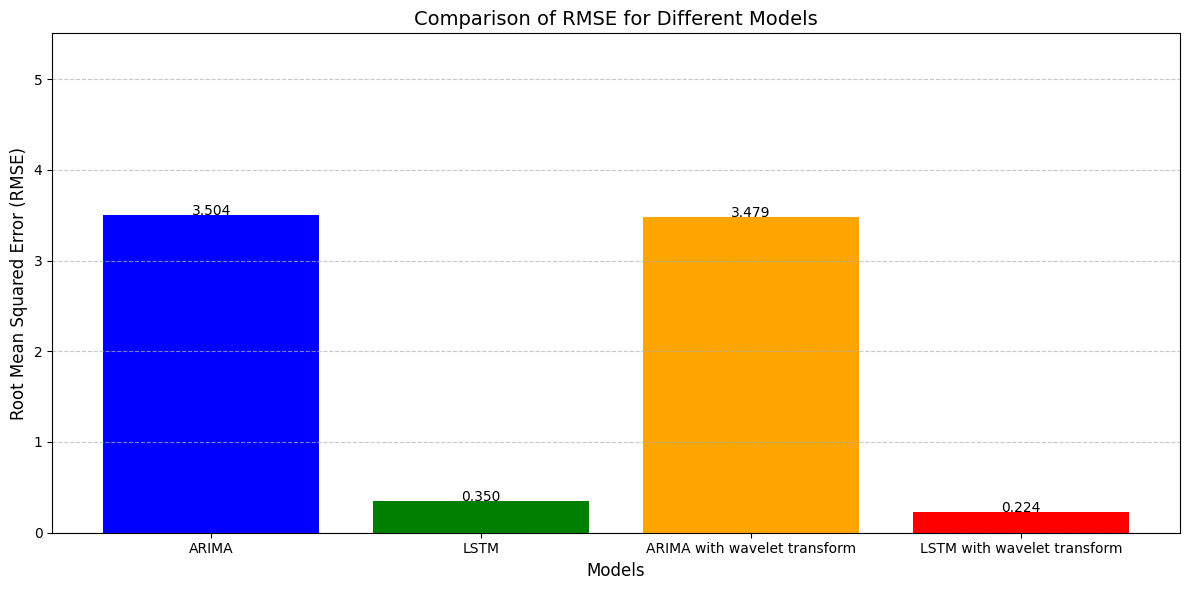

In [69]:
models = ['ARIMA', 'LSTM', 'ARIMA with wavelet transform', 'LSTM with wavelet transform']
rmse_values = [rmse1,rmse2, rmse3, rmse4]

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(models, rmse_values, color=['blue', 'green', 'orange', 'red'])

# Add labels and title
plt.xlabel('Models', fontsize=12)
plt.ylabel('Root Mean Squared Error (RMSE)', fontsize=12)
plt.title('Comparison of RMSE for Different Models', fontsize=14)
plt.ylim(0, max(rmse_values) + 2)  # Adjust y-axis for better visualization

# Annotate bars with MSE values
for i, v in enumerate(rmse_values):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=10)

# Show the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

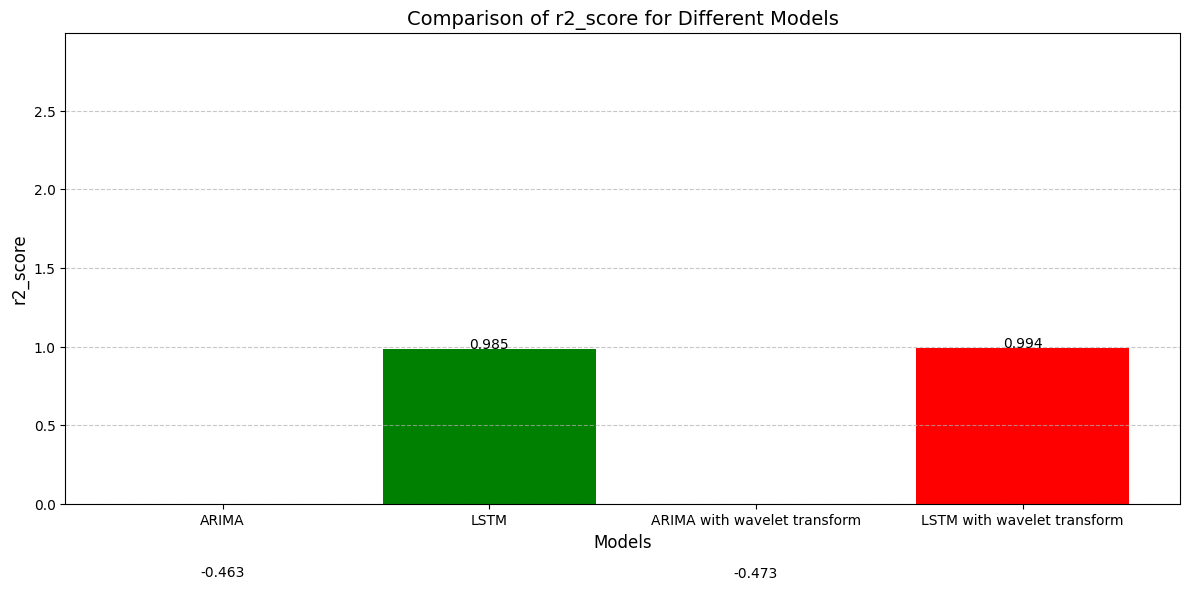

In [70]:
models = ['ARIMA', 'LSTM', 'ARIMA with wavelet transform', 'LSTM with wavelet transform']
r_score_values = [r_score1, r_score2, r_score3, r_score4]

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(models, r_score_values, color=['blue', 'green', 'orange', 'red'])

# Add labels and title
plt.xlabel('Models', fontsize=12)
plt.ylabel('r2_score', fontsize=12)
plt.title('Comparison of r2_score for Different Models', fontsize=14)
plt.ylim(0, max(r_score_values) + 2)  # Adjust y-axis for better visualization

# Annotate bars with MSE values
for i, v in enumerate(r_score_values):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=10)

# Show the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Saving the best model

In [71]:
model.save('files/lstm_model.h5')  # Saves the model in HDF5 format
print("Model saved successfully!")

Model saved successfully!
